# 질의 분해

**이 노트북에서 할 일**

1. Ch 12에서 쓰던 문서 열두 건과 질문 여덟 개를 그대로 읽습니다.
2. 자료의 질문 둘을 이어 붙여 사실이 둘 섞인 질문을 만듭니다.
3. 그 질문을 한 번만 검색해 두 근거 문서의 자리를 셉니다.
4. 같은 질문을 하위 질문 둘로 나눠 각각 검색하고 근거 문서 목록을 만듭니다.
5. 목록 셋을 Ch 12 순위 합치기로 하나로 만들어 자리를 다시 셉니다.
6. 질문만 바꾸어 같은 일을 다시 하고 두 결과를 견줍니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 아홉 번입니다(임베딩 일곱 번과 답 모델 두 번).
예상 비용은 미화 0.01달러 아래입니다.
읽어 오는 파일은 이 챕터 폴더의 문서 파일과 질문 파일 둘이고 새로 쓰는 파일은 없습니다.
실행 시간은 2분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3과 도구 파일이 쓰는 numpy 2.5.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3절부터 7절까지 읽습니다.
Ch 12 검색 부품과 순위 합치기 부품을 준비하고 사실이 둘 섞인 질문을 만드는 자리입니다.
8절과 9절은 하위 질문을 만들고 근거 문서 목록을 모으는 자리입니다.
10절부터 12절은 목록을 합치고 질문을 바꾸어 다시 재는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

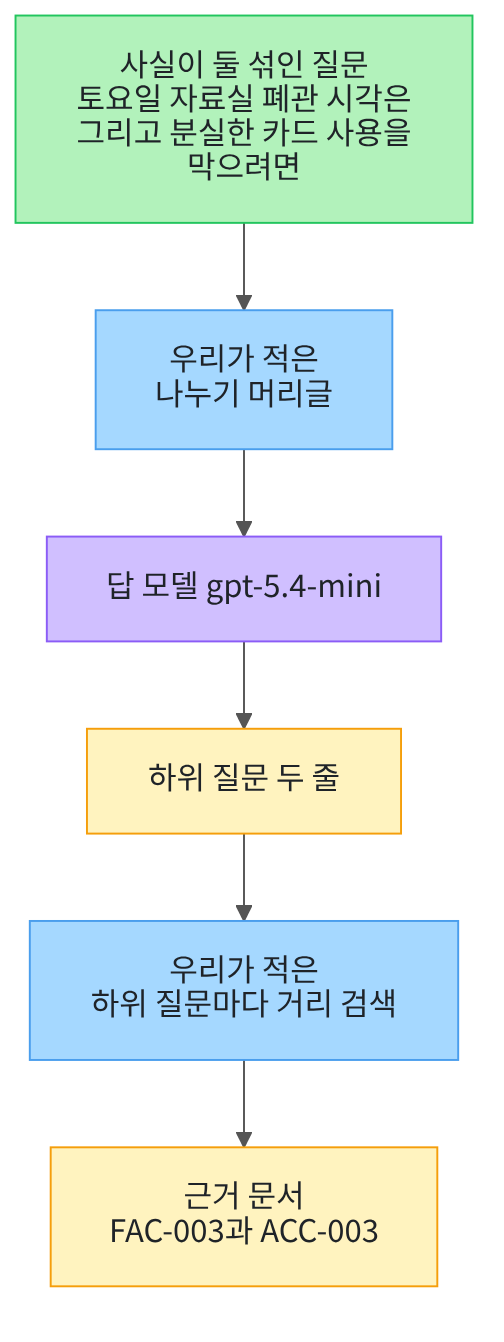

위에서 아래로 읽습니다.
맨 위 초록 상자가 사람이 적은 질문입니다.
가운데 파란 상자 둘이 우리가 적은 글과 처리이고 보라 상자가 모델입니다.
맨 아래 노란 상자 둘이 출력으로 확인한 값입니다.

## 1. 준비

첫 셀은 패키지 네 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "numpy==2.5.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 판 번호 네 줄이 보입니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이름 네 개를 불러오고 도구 파일에서 함수 일곱 개를 가져옵니다.
앞의 둘은 자료 읽기와 폴더 확인에 씁니다.
뒤의 둘은 Ch 9~13에서 쓴 임베딩과 답 모델 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 Ch 12 01절 `rank_by_distance()`와 05절 `print_ranked()`를 가져옵니다.
Ch 11 01절 `unique_doc_ids()`·`find_gold_rank()`와 Ch 12 06절 `fuse_rank()`도 가져옵니다.
02절에서 만든 `split_lines()`와 `search_ids()`도 함께 가져옵니다.
인자 모양은 5절에서 설명합니다.

In [2]:
# 자료 읽기·폴더 확인과 임베딩·답 모델 이름을 불러옵니다
import json
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model
# Ch 12 01·05·06절·Ch 11 01절 함수와 02절 함수를 도구 파일에서 가져옵니다
from rag_tools import find_gold_rank, fuse_rank, print_ranked, rank_by_distance
from rag_tools import search_ids, split_lines, unique_doc_ids

print("불러온 이름:", "json", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: json os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 네 개가 보입니다.
이름 `OpenAIEmbeddings`와 `init_chat_model`은 02절에서 쓴 것과 같습니다.
도구 파일에서 가져온 함수 일곱 개는 출력하지 않습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 01·02절과 같은 문서 파일과 질문 파일을 읽습니다.
두 파일은 Ch 12 core 벌 파일과 바이트가 같은 사본입니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리` 뒤에 점 하나나 위로 올라가는 표시가 보입니다.
Ch 10~13과 01·02절에서 쓴 방법과 같습니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 Ch 12 core 벌 그대로입니다.
문서는 도서관 안내 열두 건입니다.

질문 번호는 C01부터 C08까지이고 질문 파일에 적혀 있습니다.
이 절은 그 가운데 둘을 이어 붙여 씁니다.

## 4. 이 절에서 쓸 값 정하기

Ch 12와 01·02절에서 정한 값을 그대로 다시 적습니다.
나눌 하위 질문 개수도 여기서 못 박아 둡니다.

In [7]:
# Ch 12에서 쓴 값을 그대로 다시 정하고 나눌 하위 질문 개수도 못 박습니다
top_three = 3
top_all = 12
sub_count = 2
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)
print("나눌 하위 질문 수:", sub_count)

나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12
나눌 하위 질문 수: 2


**결과 읽기** — 출력 줄 `나란히 볼 상위 문서 수: 3`은 표로 볼 자리 수입니다.
출력 줄 `자리를 셀 때 재는 문서 수: 12`는 근거 문서의 자리를 끝까지 세려고 둔 값입니다.
출력 줄 `나눌 하위 질문 수: 2`는 이 절이 만들 하위 질문 개수입니다.

개수를 값으로 적어 두면 늘어난 요청 수를 셀 수 있습니다.
하위 질문 하나마다 임베딩 요청이 한 번씩 늘어납니다.

## 5. 앞 절 부품 준비

다음 두 셀은 01·02절에서 이미 본 준비입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
문서 글을 이어 붙이고 순위 합치기에 쓸 값 둘을 02절과 같게 적습니다.
함수는 준비 셀에서 도구 파일로 가져왔습니다.

In [8]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(Ch 12와 같은 제목 + 본문 모양)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 글:", doc_texts[0])
print("문서 ID 목록:")
print(doc_ids)

이어 붙인 글 수: 12
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


In [9]:
# Ch 12 06절 순위 합치기에 쓸 값 두 개를 02절과 같게 다시 정합니다
rank_constant = 60
base_weight = 1.0
print("순위 상수:", rank_constant)
print("목록 하나에 줄 가중치:", base_weight)

순위 상수: 60
목록 하나에 줄 가중치: 1.0


준비 셀 두 개를 지났습니다.
함수 `search_ids`는 질문 하나를 벡터로 바꿔 문서 ID 순위 목록을 만듭니다.
부를 때마다 임베딩 요청이 한 번씩 갑니다.
도구 파일 판은 임베딩 모델과 질문과 문서 벡터 목록과 문서 ID 목록과 개수를 받습니다.
함수 `fuse_rank`는 목록과 가중치 목록 뒤에 순위 상수를 셋째 인자로 받습니다.

## 6. 문서를 벡터로 바꾸기

다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [10]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 02절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 7. 사실이 둘 섞인 질문 만들기

자료의 여덟 질문은 저마다 사실 하나만 묻습니다.
그래서 질문 둘을 한 문장으로 이어 붙여 사실이 둘 섞인 질문을 만듭니다.
이어 붙이면 근거 문서 둘도 자료가 적어 둔 값 그대로 쓸 수 있습니다.

In [11]:
# 자료의 질문 둘을 한 문장으로 이어 붙여 사실이 둘 섞인 질문을 만듭니다
first_query = queries[4]
second_query = queries[7]
mixed_question = first_query["question"] + " 그리고 " + second_query["question"]
first_gold = first_query["gold_doc_id"]
second_gold = second_query["gold_doc_id"]
print("이어 붙인 질문 번호:", first_query["qid"], "|", second_query["qid"])
print("만든 질문:", mixed_question)
print("첫째 사실의 근거 문서 ID:", first_gold)
print("둘째 사실의 근거 문서 ID:", second_gold)

이어 붙인 질문 번호: C05 | C08
만든 질문: 토요일 자료실 폐관 시각은? 그리고 분실한 카드 사용을 막으려면?
첫째 사실의 근거 문서 ID: FAC-003
둘째 사실의 근거 문서 ID: ACC-003


**결과 읽기** — 출력 줄 `이어 붙인 질문 번호: C05 | C08`로 두 질문을 골랐습니다.
출력 줄 `만든 질문` 뒤에 두 물음이 한 문장으로 이어져 있습니다.
출력 줄 `첫째 사실의 근거 문서 ID: FAC-003`은 운영 시간을 적은 문서입니다.
출력 줄 `둘째 사실의 근거 문서 ID: ACC-003`은 학생증 분실을 적은 문서입니다.

실행 전에 예상해 봅니다.
질문 앞쪽 말이 운영 시간 문서와 가까우니 그쪽으로 쏠릴 것입니다.

In [12]:
# 만든 질문을 한 번만 검색해 순위 표와 두 근거 문서의 자리를 봅니다(임베딩 요청 1번)
mixed_vector = embedding_model.embed_query(mixed_question)
base_hits = rank_by_distance(mixed_vector, doc_vectors, doc_ids, top_all)
base_ids = unique_doc_ids(base_hits)
base_first = find_gold_rank(base_ids, [first_gold])
base_second = find_gold_rank(base_ids, [second_gold])
print_ranked(base_hits[:top_three], "거리")
print("한 번 검색했을 때 첫째 근거 문서의 자리:", base_first)
print("한 번 검색했을 때 둘째 근거 문서의 자리:", base_second)

순위 | 문서 ID | 거리
1 | FAC-003 | 0.62
2 | ACC-002 | 0.66
3 | FAC-004 | 0.66
한 번 검색했을 때 첫째 근거 문서의 자리: 1
한 번 검색했을 때 둘째 근거 문서의 자리: 6


**결과 읽기** — 순위 표의 차례는 `FAC-003`과 `ACC-002`와 `FAC-004`입니다.
가운데 `ACC-002`는 두 사실 어느 쪽의 근거도 아닙니다.
출력 줄 `한 번 검색했을 때 첫째 근거 문서의 자리: 1`로 앞쪽 사실은 첫 자리를 찾았습니다.
출력 줄 `한 번 검색했을 때 둘째 근거 문서의 자리: 6`으로 뒤쪽 사실은 여섯째 자리였습니다.

순위 표 둘째 줄과 셋째 줄의 거리가 `0.66`으로 같아 보입니다.
줄 세우기는 반올림 전 값으로 했고 그 두 줄의 차례는 결과로 읽지 않습니다.
거리 값은 셋째 자리 아래가 호출마다 달라져 본문과 그림에 넣지 않았습니다.

## 8. 하위 질문으로 나누기

사실 하나씩만 묻는 검색 질문을 두 줄 받습니다.
머리글에 개수와 모양을 적어 한 줄에 질문 하나만 오게 합니다.
원 질문에 없는 조건을 새로 넣지 말라는 줄도 함께 넣습니다.

In [13]:
# 머리글 네 줄과 원 질문을 한 글로 이어 붙입니다
def build_sub_prompt(question):
    sub_head = "아래 질문에는 서로 다른 사실이 섞여 있습니다.\n"
    sub_head = sub_head + "사실 하나씩만 묻는 검색 질문을 " + str(sub_count) + "줄 적으세요.\n"
    sub_head = sub_head + "한 줄에 질문 하나만 적고 번호나 기호를 붙이지 마세요.\n"
    sub_head = sub_head + "원 질문에 없는 조건을 새로 넣지 마세요.\n\n"
    prompt_text = sub_head + "질문: " + question
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_sub_prompt`는 머리글 네 줄을 이어 붙인 뒤 원 질문을 답니다.
머리글의 개수 자리에는 앞에서 정한 값 `sub_count`가 들어갑니다.
값을 바꾸면 머리글과 실제로 쓰는 개수가 함께 바뀝니다.

다음 셀은 그 글을 만들어 모델에 넣습니다.

In [14]:
# 만든 글을 모델에 넣어 하위 질문을 받습니다(모델 요청 1번)
sub_prompt = build_sub_prompt(mixed_question)
print("모델에 넣을 글:")
print(sub_prompt)
sub_reply = model.invoke(sub_prompt)
sub_text = sub_reply.text.strip()
print("모델이 쓴 글:")
print(sub_text)

모델에 넣을 글:
아래 질문에는 서로 다른 사실이 섞여 있습니다.
사실 하나씩만 묻는 검색 질문을 2줄 적으세요.
한 줄에 질문 하나만 적고 번호나 기호를 붙이지 마세요.
원 질문에 없는 조건을 새로 넣지 마세요.

질문: 토요일 자료실 폐관 시각은? 그리고 분실한 카드 사용을 막으려면?


모델이 쓴 글:
토요일 자료실 폐관 시각은 언제인가요?
분실한 카드를 사용하지 못하게 하려면 어떻게 해야 하나요?


**결과 읽기** — 라벨 줄 `모델에 넣을 글:` 아래에 머리글 네 줄과 원 질문이 있습니다.
라벨 줄 `모델이 쓴 글:` 아래에는 질문 두 줄이 있습니다.
앞 줄은 닫는 시각만 묻고 뒷줄은 분실한 카드만 묻습니다.
문장은 실행마다 달라질 수 있어 이 값에 `assert`를 걸지 않았습니다.

02절 변형 질문은 모두 같은 것을 물었습니다.
이 절 하위 질문은 서로 다른 것을 묻습니다.

## 9. 하위 질문마다 검색하기

모델이 보낸 글은 줄 하나가 질문 하나입니다.
02절에서 만든 함수로 빈 줄만 빼고 앞의 두 줄을 고릅니다.

In [15]:
# 모델이 보낸 글을 줄로 나누고 앞에서 정한 개수만 골라 씁니다
sub_lines = split_lines(sub_text)
sub_questions = sub_lines[:sub_count]
print("모델이 보낸 줄 수:", len(sub_lines))
print("쓸 하위 질문 수:", len(sub_questions))
for sub_question in sub_questions:
    print("하위 질문:", sub_question)

모델이 보낸 줄 수: 2
쓸 하위 질문 수: 2
하위 질문: 토요일 자료실 폐관 시각은 언제인가요?
하위 질문: 분실한 카드를 사용하지 못하게 하려면 어떻게 해야 하나요?


**결과 읽기** — 출력 줄 `모델이 보낸 줄 수: 2`로 두 줄이 왔습니다.
출력 줄 `쓸 하위 질문 수: 2`는 앞에서 정한 개수와 같습니다.
라벨 줄 `하위 질문:` 두 줄에 실제로 쓸 질문이 있습니다.
받은 줄이 더 많아도 앞의 두 줄만 씁니다.

적게 오면 온 만큼만 씁니다.
그때는 `쓸 하위 질문 수`가 `나눌 하위 질문 수`보다 작게 나옵니다.

다음 셀은 하위 질문마다 따로 검색합니다.

In [16]:
# 하위 질문마다 따로 검색해 첫 자리 문서를 모아 근거 문서 목록을 만듭니다(임베딩 요청 2번)
sub_rankings = []
top_hits = []
for sub_question in sub_questions:
    found_ids = search_ids(embedding_model, sub_question, doc_vectors, doc_ids, top_all)
    sub_rankings.append(found_ids)
    top_hits.append({"doc_id": found_ids[0]})
    print("하위 질문 첫 자리 문서:", found_ids[0])
evidence_ids = unique_doc_ids(top_hits)
print("근거 문서 목록:", evidence_ids)

하위 질문 첫 자리 문서: FAC-003


하위 질문 첫 자리 문서: ACC-003
근거 문서 목록: ['FAC-003', 'ACC-003']


**결과 읽기** — 라벨 줄 `하위 질문 첫 자리 문서:` 두 줄에 서로 다른 문서가 있습니다.
출력 줄 `근거 문서 목록: ['FAC-003', 'ACC-003']`이 이 절이 얻으려던 값입니다.
하위 질문 하나마다 근거 문서 하나가 짝지어졌습니다.
사실이 둘이니 근거 문서도 둘입니다.

한 번 검색했을 때는 뒤쪽 사실의 근거가 여섯째 자리였습니다.
나눠서 검색하니 그 문서가 자기 하위 질문의 첫 자리로 왔습니다.

## 10. 목록 셋을 하나로 합치기

02절은 목록 넷을 순위 합치기로 하나로 만들었습니다.
같은 방법을 이 절 목록 셋에도 써 봅니다.
원 질문 목록도 함께 넣어 하위 질문이 빗나갔을 때 기댈 자리를 남깁니다.

In [17]:
# 원 질문 목록 뒤에 하위 질문 목록 둘을 붙이고 목록마다 같은 가중치를 줍니다
ranking_list = []
weight_list = []
ranking_list.append(base_ids)
weight_list.append(base_weight)
for found_ids in sub_rankings:
    ranking_list.append(found_ids)
    weight_list.append(base_weight)
print("합칠 목록 수:", len(ranking_list))
print("쓴 가중치:", weight_list)

합칠 목록 수: 3
쓴 가중치: [1.0, 1.0, 1.0]


**결과 읽기** — 출력 줄 `합칠 목록 수: 3`으로 목록이 셋입니다.
출력 줄 `쓴 가중치: [1.0, 1.0, 1.0]`으로 세 목록을 같게 봤습니다.
첫 목록은 원 질문이고 뒤의 둘은 하위 질문입니다.

다음 셀은 세 목록을 하나로 만듭니다.

In [18]:
# 목록 셋을 순위 합치기로 하나로 만들고 두 근거 문서의 자리를 봅니다
fused_ids = fuse_rank(ranking_list, weight_list, rank_constant)
fused_first = find_gold_rank(fused_ids, [first_gold])
fused_second = find_gold_rank(fused_ids, [second_gold])
print("합친 목록의 앞 세 자리:", fused_ids[:top_three])
print("합친 뒤 첫째 근거 문서의 자리:", fused_first)
print("합친 뒤 둘째 근거 문서의 자리:", fused_second)

합친 목록의 앞 세 자리: ['FAC-004', 'LIB-002', 'ACC-002']
합친 뒤 첫째 근거 문서의 자리: 4
합친 뒤 둘째 근거 문서의 자리: 6


**결과 읽기** — 출력 줄 `합친 목록의 앞 세 자리`의 맨 앞은 `FAC-004`입니다.
그 문서는 두 사실 어느 쪽의 근거도 아닙니다.
아래 두 줄에 두 근거 문서가 몇째 자리인지 있습니다.

순위 합치기는 여러 목록에서 고르게 앞자리인 문서를 위로 올립니다.
하위 질문 둘은 다른 것을 물어 서로의 목록에서 뒷자리에 있었습니다.
그래서 고르게 앞자리인 문서가 두 사실과 상관없는 문서였습니다.
다른 것을 묻는 목록에는 하나로 합치기보다 첫 자리 문서를 따로 모으는 쪽이 맞습니다.

이번 새 커널 두 번 실행에서는 합친 뒤 두 근거의 자리가 같았습니다.
다만 하위 질문 문장이 조금 바뀌면 합친 자리도 함께 바뀌어 앞선 새 커널 실행에서는 다른 값이 나왔습니다.
그래서 이 두 숫자는 본문과 그림과 정리에 넣지 않았습니다.

## 11. 네 실행을 기록 한 줄씩으로

실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~13과 01·02절에서 쓴 기록 한 줄과 같은 모양입니다.
담는 칸만 이 절에 맞게 근거 자리 둘로 둡니다.

In [19]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, found_ids, first_place, second_place):
    row = {"실행": run_name}
    row["첫 자리 문서"] = found_ids[0]
    row["첫째 근거 자리"] = first_place
    row["둘째 근거 자리"] = second_place
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담는 칸은 실행 이름과 첫 자리 문서와 근거 자리 둘입니다.
이 절이 견주는 값이 그 넷이기 때문입니다.

다음 셀은 네 실행의 기록을 표로 출력합니다.

In [20]:
# 네 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("한 번 검색", base_ids, base_first, base_second))
for found_ids in sub_rankings:
    place_one = find_gold_rank(found_ids, [first_gold])
    place_two = find_gold_rank(found_ids, [second_gold])
    run_rows.append(run_row("하위 질문 검색", found_ids, place_one, place_two))
run_rows.append(run_row("세 목록 합치기", fused_ids, fused_first, fused_second))
print("실행 | 첫 자리 문서 | 첫째 근거 자리 | 둘째 근거 자리")
for row in run_rows:
    print(row["실행"], "|", row["첫 자리 문서"], "|", row["첫째 근거 자리"], "|", row["둘째 근거 자리"])

실행 | 첫 자리 문서 | 첫째 근거 자리 | 둘째 근거 자리
한 번 검색 | FAC-003 | 1 | 6
하위 질문 검색 | FAC-003 | 1 | 10
하위 질문 검색 | ACC-003 | 12 | 1
세 목록 합치기 | FAC-004 | 4 | 6


**결과 읽기** — 라벨 줄 `실행 | 첫 자리 문서 | 첫째 근거 자리 | 둘째 근거 자리` 아래 네 줄이 나옵니다.
첫 줄 `한 번 검색`의 근거 자리는 `1`과 `6`입니다.
가운데 두 줄에서 하위 질문마다 한쪽 근거만 첫 자리로 옵니다.
마지막 줄 `세 목록 합치기`의 첫 자리 문서는 `FAC-004`입니다.

가운데 두 줄의 뒤 숫자와 마지막 줄의 근거 자리 둘은 하위 질문 문장에 따라 달라질 수 있습니다.
그래서 본문과 그림에는 이 값들을 적지 않았습니다.

## 12. 값 바꿔 보기 · 두 사실이 한 문서에 있는 질문

바꿀 값은 검색에 쓸 질문 하나입니다.
머리글도 하위 질문 개수도 그대로 두고 질문만 바꿉니다.
이번 질문의 두 사실은 한 문서에 함께 적혀 있습니다.
실행 전에 예상해 봅니다.
하위 질문 둘이 같은 문서를 찾아 근거 문서가 하나에 그칠 것입니다.

In [21]:
# 바꿀 값은 검색에 쓸 질문 하나이고 이번에는 두 사실이 한 문서에 함께 있습니다(임베딩 요청 1번)
second_question = "휴학 중 원격 전자자료를 볼 수 있나요? 그리고 휴학 중 일반 도서를 빌릴 수 있나요?"
second_doc = "ACC-002"
second_ids = search_ids(embedding_model, second_question, doc_vectors, doc_ids, top_all)
second_place = find_gold_rank(second_ids, [second_doc])
print("바꾼 질문:", second_question)
print("두 사실이 함께 있는 문서 ID:", second_doc)
print("한 번 검색했을 때 그 문서의 자리:", second_place)

바꾼 질문: 휴학 중 원격 전자자료를 볼 수 있나요? 그리고 휴학 중 일반 도서를 빌릴 수 있나요?
두 사실이 함께 있는 문서 ID: ACC-002
한 번 검색했을 때 그 문서의 자리: 1


**결과 읽기** — 출력 줄 `바꾼 질문` 뒤에 두 물음이 한 문장으로 이어져 있습니다.
출력 줄 `두 사실이 함께 있는 문서 ID: ACC-002`는 휴학생 권한을 적은 문서입니다.
출력 줄 `한 번 검색했을 때 그 문서의 자리: 1`로 한 번 검색으로도 첫 자리였습니다.

다음 셀은 같은 머리글로 하위 질문을 다시 받습니다.

In [22]:
# 같은 머리글로 바꾼 질문을 나누어 하위 질문을 받습니다(모델 요청 1번)
second_prompt = build_sub_prompt(second_question)
second_reply = model.invoke(second_prompt)
second_text = second_reply.text.strip()
second_lines = split_lines(second_text)
second_subs = second_lines[:sub_count]
print("모델이 보낸 줄 수:", len(second_lines))
for sub_question in second_subs:
    print("하위 질문:", sub_question)

모델이 보낸 줄 수: 2
하위 질문: 휴학 중 원격 전자자료를 볼 수 있나요?
하위 질문: 휴학 중 일반 도서를 빌릴 수 있나요?


**결과 읽기** — 출력 줄 `모델이 보낸 줄 수: 2`로 이번에도 두 줄이 왔습니다.
라벨 줄 `하위 질문:` 두 줄에 원격 이용과 도서 대출을 묻는 질문이 있습니다.
문장은 실행마다 달라질 수 있습니다.

다음 셀은 하위 질문마다 같은 방법으로 검색합니다.

In [23]:
# 바꾼 질문의 하위 질문마다 검색해 같은 방법으로 근거 문서 목록을 만듭니다(임베딩 요청 2번)
second_hits = []
for sub_question in second_subs:
    found_ids = search_ids(embedding_model, sub_question, doc_vectors, doc_ids, top_all)
    second_hits.append({"doc_id": found_ids[0]})
    print("하위 질문 첫 자리 문서:", found_ids[0])
second_evidence = unique_doc_ids(second_hits)
print("근거 문서 목록:", second_evidence)

하위 질문 첫 자리 문서: ACC-002


하위 질문 첫 자리 문서: ACC-002
근거 문서 목록: ['ACC-002']


**결과 읽기** — 라벨 줄 `하위 질문 첫 자리 문서:` 두 줄이 모두 `ACC-002`입니다.
출력 줄 `근거 문서 목록: ['ACC-002']`로 근거 문서가 하나입니다.
두 사실이 한 문서에 함께 적혀 있어 나눠도 근거가 늘지 않았습니다.
나누는 일이 늘 근거를 늘리지는 않습니다.

## 정리

1. 사실이 둘 섞인 질문을 한 번만 검색하니 뒤쪽 사실의 근거가 여섯째 자리였습니다.
2. 하위 질문 둘로 나눠 검색하니 근거 문서 목록에 서로 다른 문서 둘이 담겼습니다.
3. 같은 목록 셋을 순위 합치기로 합치니 첫 자리에 두 사실의 근거가 아닌 문서가 왔습니다.
4. 두 사실이 한 문서에 있는 질문에서는 나눠도 근거 문서가 하나였습니다.

04절에서는 질문을 잘게 나누는 대신 한 단계 넓혀 일반 규칙을 찾습니다.
이 절이 만든 하위 질문은 원 질문보다 좁고 04절 질문은 원 질문보다 넓습니다.